# Experiment 5 - Graphs with correct labels

This notebook redraws the graphs of Experiment 5 from the saved results, without running the games again.

Experiment 5 passed `reads_own_reasoning=ephemeral` to the agent, so the labels of $r4$ and $r10$ are swapped:
- the files `r{n}think_*.pickle` contain the **ephemeral** runs;
- the files `er{n}think_*.pickle` contain the **non-ephemeral** runs.

$e1$ and $0$ are not affected. Here every file is assigned its correct label.

In [2]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Data loading

In [3]:
results_folder = "./Experiment 5"
graphs_folder = f"{results_folder}/graphs_corrected"

with open("./Experiment 1/max_scores.pickle", "rb") as f:
    max_scores_simple = np.array(pickle.load(f)[:50])
max_score_cooking = 5

# correct label: (file prefix, group on the x axis, box color, mean marker color)
configurations = {
    "e1-think":            ("e1think",   "topline",  "#55a868", "#3a944f"),
    "r4-think":            ("er4think",  "4-think",  "#64b5cd", "#449bb6"), # file labeled "e" but NOT ephemeral
    "ephemeral r4-think":  ("r4think",   "4-think",  "#5191a5", "#357a8f"), # file labeled without "e" but ephemeral
    "r10-think":           ("er10think", "10-think", "#ccb974", "#b49f53"),
    "ephemeral r10-think": ("r10think",  "10-think", "#a0915b", "#807038"),
    "0-think":             ("0think",    "baseline", "#c44e52", "#aa2e32"),
}

# each pickle is a list with one run per seed, each run a list of (moves, score, time) per step
scores = {"simple": {}, "cooking": {}}
times = {"simple": {}, "cooking": {}}
for game, max_scores in [("simple", max_scores_simple), ("cooking", max_score_cooking)]:
    for label, (prefix, _, _, _) in configurations.items():
        with open(f"{results_folder}/{prefix}_{game}.pickle", "rb") as f:
            results_all_seeds = pickle.load(f)
        scores[game][label] = np.array([run[-1][1] for run in results_all_seeds]) / max_scores
        times[game][label] = np.array([run[-1][2] for run in results_all_seeds])
print("Data loaded.")

Data loaded.


# Means

In [4]:
pd.DataFrame({
    "simple: score": {label: np.mean(v) for label, v in scores["simple"].items()},
    "cooking: score": {label: np.mean(v) for label, v in scores["cooking"].items()},
    "simple: time [s]": {label: np.mean(v) for label, v in times["simple"].items()},
    "cooking: time [s]": {label: np.mean(v) for label, v in times["cooking"].items()},
}).round(3)

,simple: score,cooking: score,simple: time [s],cooking: time [s]
e1-think,1.000,0.480,163.493,879.378
r4-think,0.886,0.252,73.026,189.252
ephemeral r4-think,0.920,0.420,88.291,347.274
r10-think,0.864,0.204,56.486,169.280
ephemeral r10-think,0.916,0.248,64.422,231.209
0-think,0.746,0.064,27.113,31.545


# Visualization

In [5]:
figsize = (15, 6)
group_positions = {"topline": 0, "4-think": 1, "10-think": 2, "baseline": 3}
dodge = 0.2 # horizontal offset of the two boxes in the same group

def box_positions():
    """x position of every configuration: centered if alone in its group, side by side otherwise."""
    positions = {}
    for group, x in group_positions.items():
        labels = [label for label, c in configurations.items() if c[1] == group]
        for i, label in enumerate(labels):
            positions[label] = x + (i - (len(labels) - 1) / 2) * 2 * dodge
    return positions

def plot(data, ylabel, title, filename, log=False):
    fig, ax = plt.subplots(figsize=figsize)
    positions = box_positions()
    for label, (_, _, color, mean_color) in configurations.items():
        box = ax.boxplot(data[label], positions=[positions[label]], widths=0.35,
                         patch_artist=True, flierprops={"marker": "x"},
                         medianprops={"color": "black"})
        box["boxes"][0].set(facecolor=color, alpha=0.5)
        ax.plot(positions[label], np.mean(data[label]), marker="^", markersize=12,
                color=mean_color, markeredgecolor="white")
    ax.set_xticks(list(group_positions.values()), list(group_positions.keys()))
    handles = [Patch(facecolor=c[2], alpha=0.5, label=label) for label, c in configurations.items()]
    handles.append(Line2D([], [], marker="^", color="gray", linestyle="", markersize=12, label="mean"))
    ax.legend(handles=handles)
    ax.grid(axis="y", alpha=0.5)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if log:
        ax.semilogy()
    os.makedirs(graphs_folder, exist_ok=True)
    fig.savefig(f"{graphs_folder}/{filename}.pdf", bbox_inches="tight")
    plt.show()

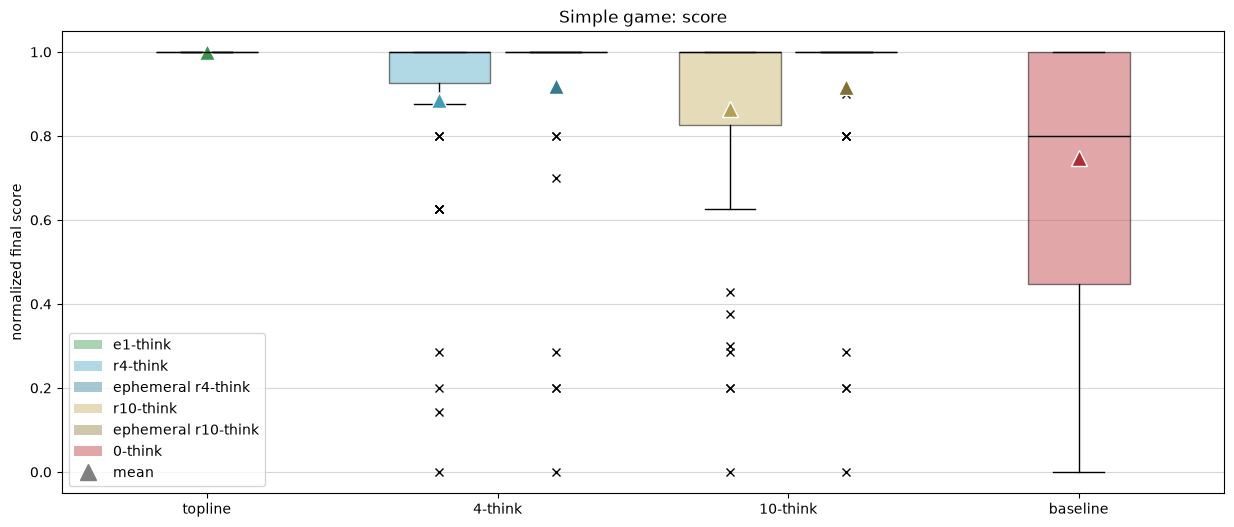

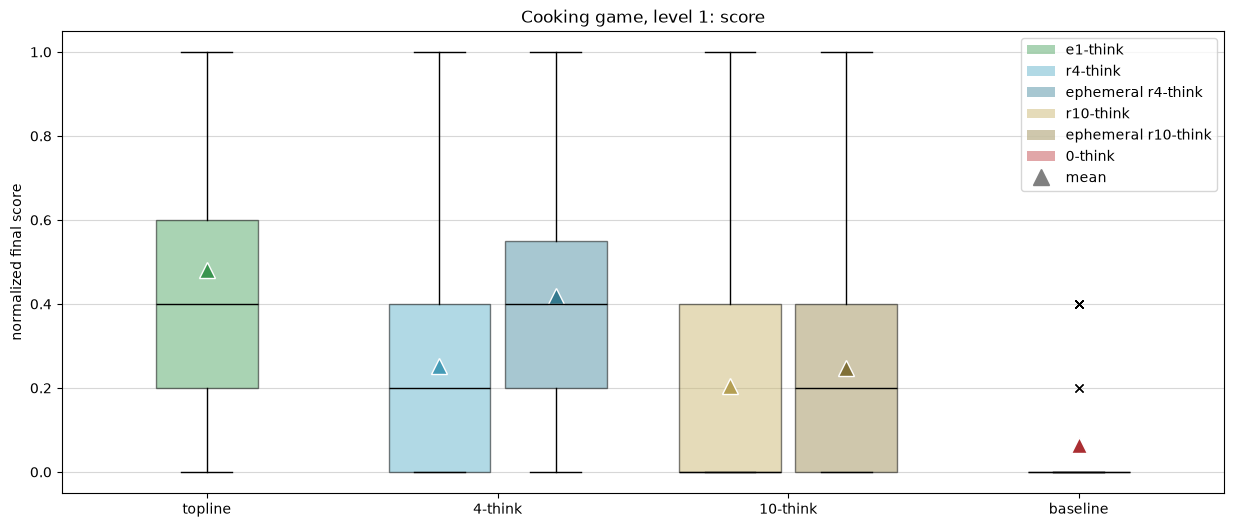

In [6]:
plot(scores["simple"], "normalized final score", "Simple game: score", "score_simple")
plot(scores["cooking"], "normalized final score", "Cooking game, level 1: score", "score_cooking")

Execution times are CPU times (`time.process_time()`) of a whole game, in seconds. They are not divided by the maximum score.

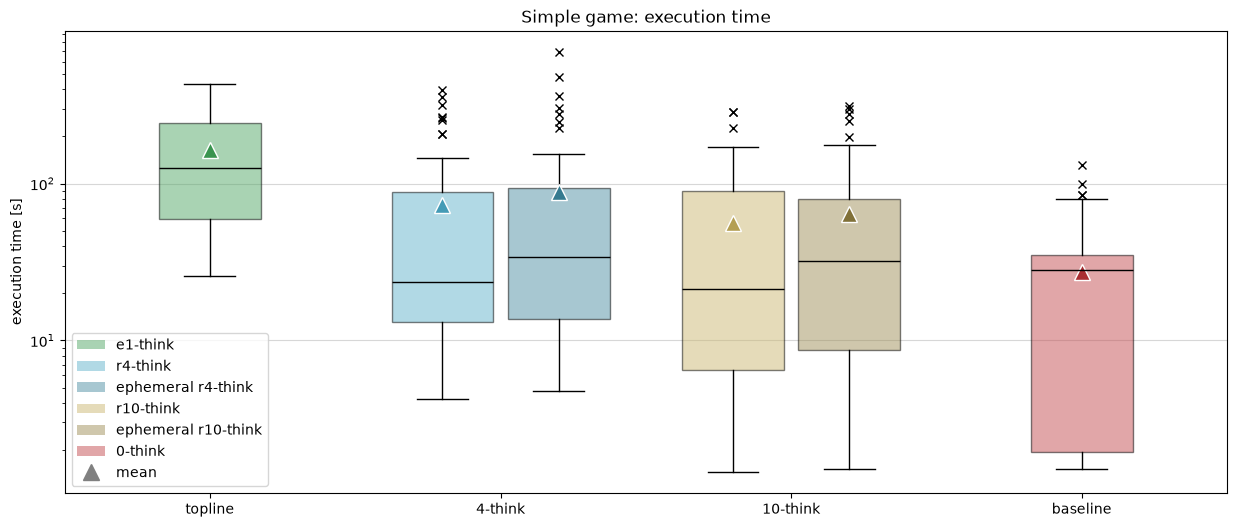

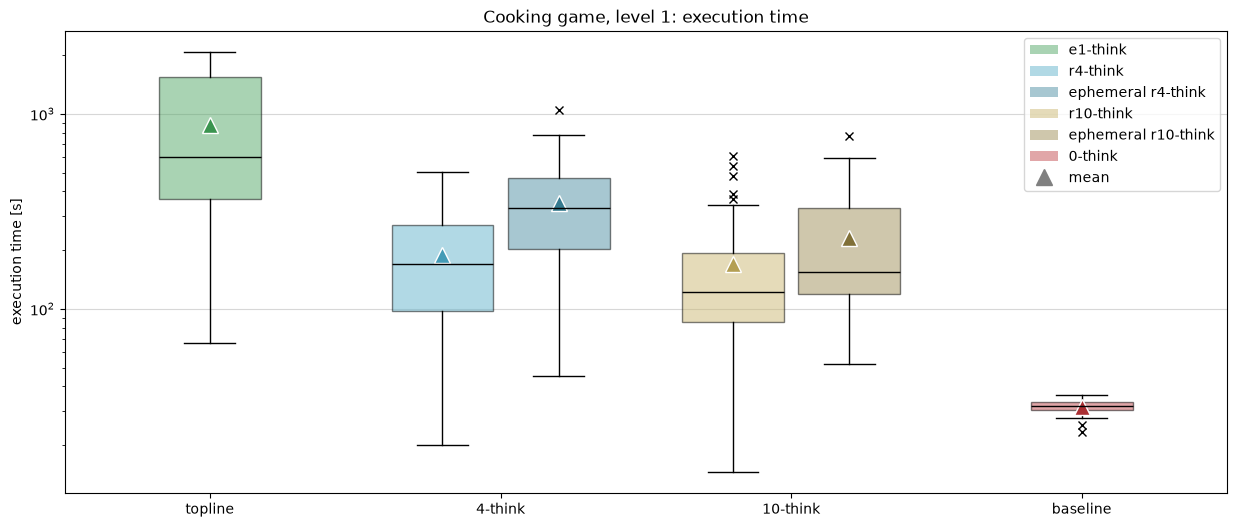

In [7]:
plot(times["simple"], "execution time [s]", "Simple game: execution time", "time_simple", log=True)
plot(times["cooking"], "execution time [s]", "Cooking game, level 1: execution time", "time_cooking", log=True)